# 📱 Will the Customer Switch? — Model Practice

**TeleOne**, a mobile operator, wants to know which customers will move to another operator in the next 3 months, so it can offer them a deal before they leave.

You have data on **600 customers** in `mobile_customers.csv`.

**Your job**
1. Build three models: **KNN**, **Logistic Regression** and **Decision Tree**.
2. For every model, compare **train accuracy** with **test accuracy**.
3. Find which settings **overfit**, which **underfit**, and which give a **good fit**.
4. Pick the model you would give to TeleOne.

Section 1 is already written for you. Run it, then write your own code in every cell marked `# Your code here`.

### 📋 Columns

| Column | Meaning |
|---|---|
| `customer_id` | Customer ID (not useful for prediction) |
| `age` | Age of the customer |
| `plan_type` | `Prepaid` or `Postpaid` |
| `monthly_bill` | Monthly bill in ₹ |
| `data_gb_per_month` | Mobile data used per month (GB) — has some blanks |
| `call_drops_per_week` | Calls dropped per week |
| `months_with_operator` | How long they have been with TeleOne — has some blanks |
| `complaints_last_3m` | Complaints made in the last 3 months |
| `city_tier` | `Tier-1`, `Tier-2` or `Tier-3` city |
| `has_family_plan` | `Yes` or `No` |
| **`switched`** | **Target:** 1 = moved to another operator, 0 = stayed |

### 🔁 Quick recap

| What you see | Name |
|---|---|
| Train accuracy **high**, test accuracy **much lower** | **Overfitting** (the model memorised the training rows) |
| Train accuracy **low** and test accuracy **low** | **Underfitting** (the model is too simple) |
| Train and test both **high** and **close** to each other | **Good fit** |

## ✅ Section 1 — Setup (already done, just run)

> **Flow:** import → load → drop the ID column → split → build the preprocessing step → helper function

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("mobile_customers.csv")
print(df.shape)
df.head()

(600, 11)


,customer_id,age,plan_type,monthly_bill,data_gb_per_month,call_drops_per_week,months_with_operator,complaints_last_3m,city_tier,has_family_plan,switched
0,MC1001,59,Prepaid,349,14.0,3,96.0,2,Tier-2,No,0
1,MC1002,24,Postpaid,829,23.1,2,18.0,1,Tier-2,No,1
2,MC1003,25,Prepaid,199,18.2,7,35.0,1,Tier-3,Yes,1
3,MC1004,56,Prepaid,279,38.8,2,NaN,1,Tier-1,No,0
4,MC1005,25,Postpaid,749,20.1,2,51.0,0,Tier-2,Yes,0


In [4]:
# Blanks in each column
df.isna().sum()

customer_id              0
age                      0
plan_type                0
monthly_bill             0
data_gb_per_month       21
call_drops_per_week      0
months_with_operator    18
complaints_last_3m       0
city_tier                0
has_family_plan          0
switched                 0
dtype: int64

In [5]:
# customer_id is only a label, so we drop it. switched is the target.
X = df.drop(columns=["customer_id", "switched"])
y = df["switched"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Train rows: 450 | Test rows: 150


In [6]:
num_cols = ["age", "monthly_bill", "data_gb_per_month", "call_drops_per_week",
            "months_with_operator", "complaints_last_3m"]
cat_cols = ["plan_type", "city_tier", "has_family_plan"]

# Number columns: fill blanks with the median, then scale.
# Text columns: one-hot encode.
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(), cat_cols),
])

In [7]:
def train_test_accuracy(model):
    """Fit the model on the training data and return (train accuracy, test accuracy)."""
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    return round(train_acc, 3), round(test_acc, 3)

# How to use it (from Task 2.2 onward):
# train_acc, test_acc = train_test_accuracy(my_pipeline)

## 🔵 Section 2 — KNN

> **Flow:** build a Pipeline → fit → train vs test accuracy → change `k` → find overfitting and underfitting

**Task 2.1** — Build a `Pipeline` with two steps: `("prep", preprocess)` and `("model", KNeighborsClassifier(n_neighbors=5))`.
Fit it on the training data and print the **train accuracy** and the **test accuracy**. Write this one yourself, without the helper.

In [8]:
# Your code here
knn_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

train_acc, test_acc = train_test_accuracy(knn_pipeline)

print("Train accuracy:", train_acc)
print("Test accuracy:", test_acc)


Train accuracy: 0.878
Test accuracy: 0.787


**Task 2.2** — Try `k = 1, 5, 15, 51, 201`. For each `k`, build the pipeline and use `train_test_accuracy()`.
Store the results in a DataFrame called `knn_results` with columns `k`, `train_acc`, `test_acc`.

*Hint:* make an empty list, append a dictionary for each `k`, then `pd.DataFrame(your_list)`.

In [9]:
# Your code here

knn_results_list = []

for k in [1, 5, 15, 51, 201]:
    knn_pipeline = Pipeline([
        ("prep", preprocess),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])

    train_acc, test_acc = train_test_accuracy(knn_pipeline)

    knn_results_list.append({
        "k": k,
        "train_acc": train_acc,
        "test_acc": test_acc
    })

knn_results = pd.DataFrame(knn_results_list)
print(knn_results)


     k  train_acc  test_acc
0    1      1.000     0.713
1    5      0.878     0.787
2   15      0.827     0.773
3   51      0.811     0.780
4  201      0.733     0.667


**Task 2.3** — Plot train accuracy and test accuracy against `k` on the same chart with `sns.lineplot` (one call for each line, use `marker="o"` and `label=`).

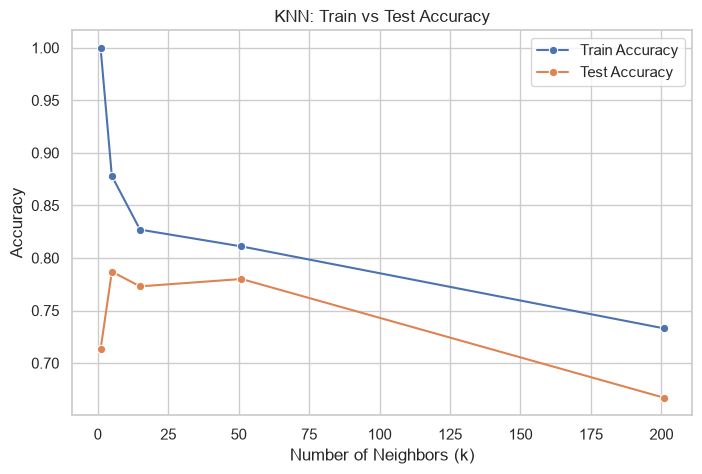

In [10]:
# Your code here

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=knn_results,
    x="k",
    y="train_acc",
    marker="o",
    label="Train Accuracy"
)

sns.lineplot(
    data=knn_results,
    x="k",
    y="test_acc",
    marker="o",
    label="Test Accuracy"
)

plt.title("KNN: Train vs Test Accuracy")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


**Questions** — Which `k` overfits?

Usually, k = 1 overfits because it is very sensitive to individual training examples (so, training accuracy is 1 while testing accuracy is much less: 0.713).

 Which `k` underfits?
 
 A very large k, such as k = 201, may underfit because it considers too many neighbors and can oversimplify the decision boundary (so, training accuracy and testing accuracy both are very less, 0.733 and 0.667).

  Which `k` would you choose?

 I would choose the k with the highest test accuracy, provided the train-test accuracy gap is reasonably small (k=5 for example).



## 🟢 Section 3 — Logistic Regression

> **Flow:** build a Pipeline → train vs test accuracy → confusion matrix → precision and recall

**Task 3.1** — Build a pipeline with `LogisticRegression()` and find its train and test accuracy with `train_test_accuracy()`.

In [11]:
# Your code here

logistic_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000))
])

log_train_acc, log_test_acc = train_test_accuracy(logistic_pipeline)

print("Train accuracy:", log_train_acc)
print("Test accuracy:", log_test_acc)


Train accuracy: 0.858
Test accuracy: 0.84


**Task 3.2** — On the **test** data, make the confusion matrix and show it with `sns.heatmap(..., annot=True, fmt="d")`.
Then print the **precision** and **recall** for customers who switched (class 1).

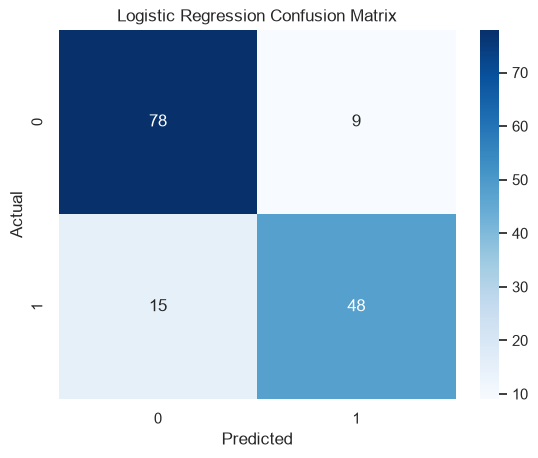

Precision: 0.842
Recall: 0.762


In [19]:
# Your code here

from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_pred_log = logistic_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred_log)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

precision = precision_score(y_test, y_pred_log, zero_division=0)
recall = recall_score(y_test, y_pred_log, zero_division=0)

print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))


**Question** — Is Logistic Regression overfitting? Look at the gap between train and test accuracy.

Train accuracy: 0.858

Test accuracy: 0.84

Logistic Regression is a good fit and not overfitting as the gap between training accuracy and test accuracy is quite less and test accuracy is also quite high.

## 🌳 Section 4 — Decision Tree

> **Flow:** tree with no limit → tree with `max_depth=1` → try every depth → plot → pick the best depth

**Task 4.1** — Build a pipeline with `DecisionTreeClassifier(random_state=42)` (no `max_depth`). Find train and test accuracy.

In [20]:
# Your code here

tree_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_train_acc, tree_test_acc = train_test_accuracy(tree_pipeline)

print("Train accuracy:", tree_train_acc)
print("Test accuracy:", tree_test_acc)


Train accuracy: 1.0
Test accuracy: 0.68


**Task 4.2** — Do the same with `max_depth=1`.

In [21]:
# Your code here

shallow_tree_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeClassifier(max_depth=1, random_state=42))
])

shallow_train_acc, shallow_test_acc = train_test_accuracy(
    shallow_tree_pipeline
)

print("Train accuracy:", shallow_train_acc)
print("Test accuracy:", shallow_test_acc)


Train accuracy: 0.738
Test accuracy: 0.693


**Task 4.3** — Try `max_depth` from 1 to 12. Store the results in `tree_results` (columns `max_depth`, `train_acc`, `test_acc`) and plot both lines with `sns.lineplot`.

    max_depth  train_acc  test_acc
0           1      0.738     0.693
1           2      0.749     0.673
2           3      0.820     0.787
3           4      0.867     0.793
4           5      0.893     0.800
5           6      0.927     0.707
6           7      0.956     0.687
7           8      0.969     0.700
8           9      0.987     0.693
9          10      0.993     0.673
10         11      0.993     0.680
11         12      0.998     0.673


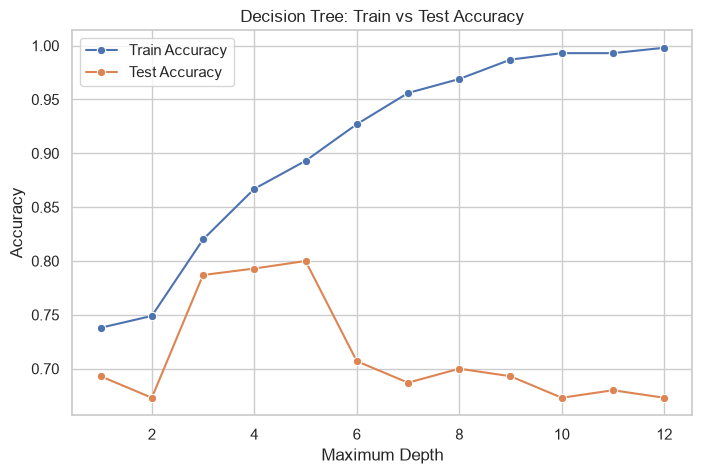

In [22]:
# Your code here
tree_results_list = []

for depth in range(1, 13):
    tree_pipeline = Pipeline([
        ("prep", preprocess),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    train_acc, test_acc = train_test_accuracy(tree_pipeline)

    tree_results_list.append({
        "max_depth": depth,
        "train_acc": train_acc,
        "test_acc": test_acc
    })

tree_results = pd.DataFrame(tree_results_list)

print(tree_results)

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=tree_results,
    x="max_depth",
    y="train_acc",
    marker="o",
    label="Train Accuracy"
)

sns.lineplot(
    data=tree_results,
    x="max_depth",
    y="test_acc",
    marker="o",
    label="Test Accuracy"
)

plt.title("Decision Tree: Train vs Test Accuracy")
plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


**Questions** — From your table and plot:
1. What happens to **train** accuracy as `max_depth` grows? What happens to **test** accuracy?

    Training accuracy generally increases or stays the same because the tree can learn more complex patterns. Test accuracy may initially increase, but it decreases if the tree starts overfitting.

2. Which `max_depth` gives the best test accuracy?

    max_depth = 5

In [25]:
best_tree_row = tree_results.loc[tree_results["test_acc"].idxmax()]

print("Best max_depth:", best_tree_row["max_depth"])
print("Best test accuracy:", best_tree_row["test_acc"])

Best max_depth: 5.0
Best test accuracy: 0.8


## 📊 Section 5 — Compare all models

> **Flow:** one table with every model → gap = train − test → label each model

**Task 5.1** — Make a DataFrame called `summary` with one row per model and columns `model`, `train_acc`, `test_acc`:

- KNN (k=1)
- KNN (your best k)
- KNN (k=201)
- Logistic Regression
- Decision Tree (no limit)
- Decision Tree (max_depth=1)
- Decision Tree (your best depth)

Then add a column `gap` = `train_acc` − `test_acc`.

*Hint:* you already have most numbers in `knn_results`, `tree_results` and your variables from Sections 3 and 4.

In [26]:
# Your code here
# Find the best k from the KNN results
best_knn_row = knn_results.loc[knn_results["test_acc"].idxmax()]
best_k = int(best_knn_row["k"])

# Find the best decision tree depth
best_tree_row = tree_results.loc[tree_results["test_acc"].idxmax()]
best_depth = int(best_tree_row["max_depth"])

# Get KNN results for k=1 and k=201
knn_k1 = knn_results.loc[knn_results["k"] == 1].iloc[0]
knn_k201 = knn_results.loc[knn_results["k"] == 201].iloc[0]

# Get the best KNN row
best_knn = knn_results.loc[knn_results["k"] == best_k].iloc[0]

# Build the summary table
summary = pd.DataFrame([
    {
        "model": "KNN (k=1)",
        "train_acc": knn_k1["train_acc"],
        "test_acc": knn_k1["test_acc"]
    },
    {
        "model": f"KNN (k={best_k})",
        "train_acc": best_knn["train_acc"],
        "test_acc": best_knn["test_acc"]
    },
    {
        "model": "KNN (k=201)",
        "train_acc": knn_k201["train_acc"],
        "test_acc": knn_k201["test_acc"]
    },
    {
        "model": "Logistic Regression",
        "train_acc": log_train_acc,
        "test_acc": log_test_acc
    },
    {
        "model": "Decision Tree (no limit)",
        "train_acc": tree_train_acc,
        "test_acc": tree_test_acc
    },
    {
        "model": "Decision Tree (max_depth=1)",
        "train_acc": shallow_train_acc,
        "test_acc": shallow_test_acc
    },
    {
        "model": f"Decision Tree (depth={best_depth})",
        "train_acc": best_tree_row["train_acc"],
        "test_acc": best_tree_row["test_acc"]
    }
])

summary["gap"] = summary["train_acc"] - summary["test_acc"]

print(summary)


                         model  train_acc  test_acc    gap
0                    KNN (k=1)      1.000     0.713  0.287
1                    KNN (k=5)      0.878     0.787  0.091
2                  KNN (k=201)      0.733     0.667  0.066
3          Logistic Regression      0.858     0.840  0.018
4     Decision Tree (no limit)      1.000     0.680  0.320
5  Decision Tree (max_depth=1)      0.738     0.693  0.045
6      Decision Tree (depth=5)      0.893     0.800  0.093


**Task 5.2** — Add a column `verdict` using these rules (use `.loc` with a condition):

- `gap` more than **0.10** → `"Overfitting"`
- `gap` 0.10 or less **and** `test_acc` below **0.75** → `"Underfitting"`
- everything else → `"Good fit"`

In [ ]:
# Your code here
summary["verdict"] = "Good fit"

summary.loc[
    summary["gap"] > 0.10,
    "verdict"
] = "Overfitting"

summary.loc[
    (summary["gap"] <= 0.10) &
    (summary["test_acc"] < 0.75),
    "verdict"
] = "Underfitting"

print(summary)


                         model  train_acc  test_acc    gap       verdict
0                    KNN (k=1)      1.000     0.713  0.287   Overfitting
1                    KNN (k=5)      0.878     0.787  0.091      Good fit
2                  KNN (k=201)      0.733     0.667  0.066  Underfitting
3          Logistic Regression      0.858     0.840  0.018      Good fit
4     Decision Tree (no limit)      1.000     0.680  0.320   Overfitting
5  Decision Tree (max_depth=1)      0.738     0.693  0.045  Underfitting
6      Decision Tree (depth=5)      0.893     0.800  0.093      Good fit


In [28]:
best_model = summary.loc[summary["test_acc"].idxmax()]

print("Best model:", best_model["model"])
print("Train accuracy:", best_model["train_acc"])
print("Test accuracy:", best_model["test_acc"])
print("Accuracy gap:", best_model["gap"])
print("Verdict:", best_model["verdict"])


Best model: Logistic Regression
Train accuracy: 0.858
Test accuracy: 0.84
Accuracy gap: 0.018000000000000016
Verdict: Good fit


**Question** — Which model would you give to TeleOne, and why? Use your `summary` table.

I would choose the 'Logistic Regression' model as it has the highest test accuracy and a reasonably small train-test accuracy gap. This model would predict whether customers will switch operators accurately on unseen data while avoiding significant overfitting.

## ⭐ Section 6 — Bonus: Random Forest (optional)

We will learn Random Forest in the next class. For now, build it the same way and compare.

**Task 6.1** — Build a pipeline with `RandomForestClassifier(random_state=42)`, find train and test accuracy, and compare it with **Decision Tree (no limit)**.

In [29]:
# Your code here

from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(random_state=42))
])

forest_train_acc, forest_test_acc = train_test_accuracy(
    forest_pipeline
)

print("Random Forest Train accuracy:", forest_train_acc)
print("Random Forest Test accuracy:", forest_test_acc)

print("\nDecision Tree (no limit)")
print("Train accuracy:", tree_train_acc)
print("Test accuracy:", tree_test_acc)

forest_comparison = pd.DataFrame([
    {
        "model": "Decision Tree (no limit)",
        "train_acc": tree_train_acc,
        "test_acc": tree_test_acc
    },
    {
        "model": "Random Forest",
        "train_acc": forest_train_acc,
        "test_acc": forest_test_acc
    }
])

print("\nComparison:")
print(forest_comparison)


Random Forest Train accuracy: 1.0
Random Forest Test accuracy: 0.82

Decision Tree (no limit)
Train accuracy: 1.0
Test accuracy: 0.68

Comparison:
                      model  train_acc  test_acc
0  Decision Tree (no limit)        1.0      0.68
1             Random Forest        1.0      0.82


**Question** — Both have very high train accuracy. Which one does better on the test data?

The model with the higher test accuracy (Random Forest) performs better on unseen data. Random Forest often generalizes better than a single unrestricted Decision Tree because it combines multiple trees.

## 📝 Section 7 — Quick check

Answer in one line each.

**Q1.** Your teammate at TeleOne trained a model and reports **train accuracy 99%** and **test accuracy 70%**. What is happening, and what would you change in a decision tree?

The model is overfitting because training accuracy is much higher than test accuracy. I would reduce the Decision Tree's `max_depth` to make it simpler and improve generalization.

**Q2.** Another model gives **train accuracy 62%** and **test accuracy 60%**. What is happening?

The model is underfitting because both training and test accuracy are low and similar. I would use a more complex model or adjust its parameters to learn the patterns (training data) better.

**Q3.** In KNN, does `k = 1` behave like a very deep tree or like a `max_depth=1` tree? Why?

`k = 1` behaves more like a very deep Decision Tree because it can create a highly complex decision boundary and is sensitive to individual training examples, which can lead to overfitting.